<h1> Baseline Models<h1/>

<h3> Import Libraries <h3/>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import joblib

### Import Classification Metrics

In [2]:
from sklearn.metrics import classification_report,ConfusionMatrixDisplay

<h3>Load Models And Data<h3/>

In [3]:
pca_model=joblib.load(r'../DATA/covertype/pca_model.pkl')
scaler=joblib.load(r'../DATA/covertype/scaler.pkl')
decomposited_x_train_data=pd.read_csv(r'../DATA/covertype/decomposited_Train_data.csv').values
y_train=pd.read_csv(r'../DATA/covertype/y_train.csv').values.ravel()
x_eval_scaled=pd.read_csv(r'../DATA/covertype/x_eval_scaled.csv')
y_eval=pd.read_csv(r'../DATA/covertype/y_eval.csv').values.ravel()

The `ravel()` method was applied to the training, validation, and test target data to convert the target arrays from a two-dimensional column vector into a one-dimensional array. This format is required by most scikit-learn models and helps avoid shape-related warnings during model training and evaluation.


### Applying PCA to Evaluation Data

The PCA model was previously fitted and applied to the training data. The same PCA model is now used to transform the evaluation data, ensuring that both datasets are represented in the same reduced feature space.


In [4]:
decomposited_x_eval_data=pca_model.transform(x_eval_scaled.values)

### Baseline Model Evaluation

First, the selected models are trained using their default hyperparameter settings. Their performance is then evaluated on the validation set to establish a baseline. This provides a reference point for determining whether hyperparameter tuning can meaningfully improve the models' performance.


### The trained model will be used to make predictions on the evaluation data. Its performance was then evaluated by comparing the predicted labels with the actual labels to assess how well the model performs on unseen data.

<h3>1. Logistic Regression<h3/>

In [6]:
from sklearn.linear_model import LogisticRegression
logistic_model=LogisticRegression(max_iter=1000)

### Fit Logistic Regression Model on Train Data<h3/>

In [8]:
logistic_model.fit(decomposited_x_train_data,y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mul

### Logistic Regression Model Prediction and Evaluation on Evaluation Data


In [9]:
logistic_predict=logistic_model.predict(decomposited_x_eval_data)

In [10]:
print(classification_report(y_eval,logistic_predict))

              precision    recall  f1-score   support

           1       0.70      0.69      0.69     31776
           2       0.74      0.80      0.77     42496
           3       0.67      0.82      0.74      5363
           4       0.66      0.44      0.53       412
           5       0.31      0.01      0.02      1424
           6       0.48      0.21      0.30      2605
           7       0.71      0.54      0.62      3076

    accuracy                           0.72     87152
   macro avg       0.61      0.50      0.52     87152
weighted avg       0.71      0.72      0.71     87152



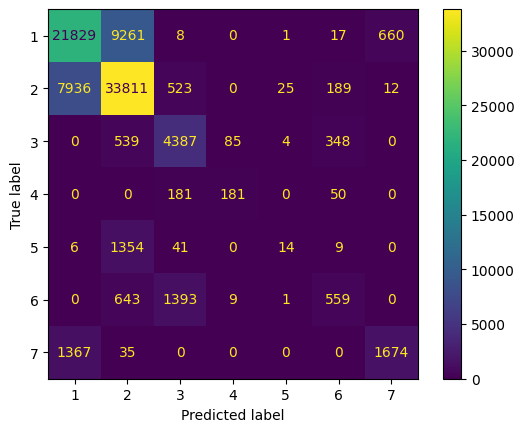

In [11]:
ConfusionMatrixDisplay.from_predictions(y_eval,logistic_predict)

<h3>2. KNN<h3/>

In [12]:
from sklearn.neighbors import KNeighborsClassifier
KNN_model=KNeighborsClassifier()

### Fit KNN Model on Train Data<h3/>

In [13]:
KNN_model.fit(decomposited_x_train_data,y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.Doesn't affect :meth:`fit` method.",None


### KNN Model Prediction and Evaluation on Evaluation Data


In [14]:
KNN_predict=KNN_model.predict(decomposited_x_eval_data)

In [15]:
print(classification_report(y_eval,KNN_predict))

              precision    recall  f1-score   support

           1       0.91      0.90      0.91     31776
           2       0.91      0.93      0.92     42496
           3       0.85      0.87      0.86      5363
           4       0.77      0.70      0.73       412
           5       0.80      0.69      0.74      1424
           6       0.76      0.71      0.74      2605
           7       0.93      0.90      0.92      3076

    accuracy                           0.90     87152
   macro avg       0.85      0.82      0.83     87152
weighted avg       0.90      0.90      0.90     87152



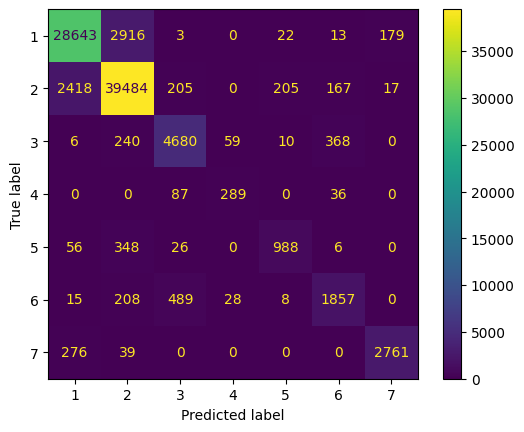

In [16]:
ConfusionMatrixDisplay.from_predictions(y_eval,KNN_predict)

### 3. Naive Bayes



The Gaussian Naive Bayes model was selected because the Covertype dataset mainly contains continuous numerical features, such as elevation, slope, distances, and hillshade measurements. Gaussian Naive Bayes is well suited for continuous features, as it assumes that the feature values follow a Gaussian (normal) distribution within each class.


In [17]:
from sklearn.naive_bayes import GaussianNB
NB_model=GaussianNB()

### Fit Naive Bayes Model on Train Data<h3/>

In [18]:
NB_model.fit(decomposited_x_train_data,y_train)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09


### Naive Bayes Model Prediction and Evaluation on Evaluation Data


In [19]:
NB_predict=NB_model.predict(decomposited_x_eval_data)

In [20]:
print(classification_report(y_eval,NB_predict))

              precision    recall  f1-score   support

           1       0.46      0.86      0.60     31776
           2       0.91      0.08      0.14     42496
           3       0.57      0.58      0.57      5363
           4       0.11      0.68      0.19       412
           5       0.06      0.55      0.10      1424
           6       0.12      0.02      0.03      2605
           7       0.36      0.17      0.23      3076

    accuracy                           0.41     87152
   macro avg       0.37      0.42      0.27     87152
weighted avg       0.67      0.41      0.33     87152



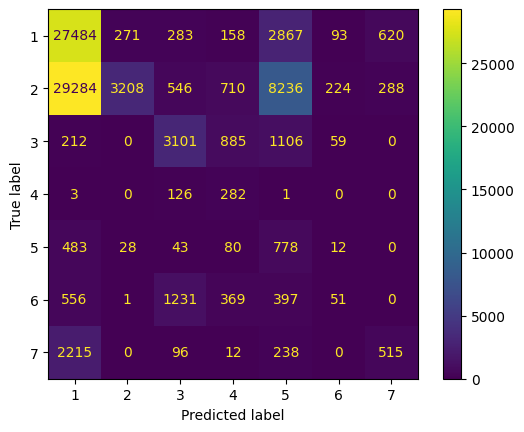

In [21]:
ConfusionMatrixDisplay.from_predictions(y_eval,NB_predict)

### 4. SVM
LinearSVC was selected as an alternative to the standard SVC because the Covertype dataset contains a large number of samples. The standard SVC can be computationally expensive on large datasets, while LinearSVC is more efficient and scalable for large-scale classification. Therefore, LinearSVC provides a more practical choice while still allowing us to evaluate the performance of a linear Support Vector Machine.

In [22]:
from sklearn.svm import LinearSVC
svc_model=LinearSVC(max_iter=2000)

### Fit SVC Model on Train Data<h3/>

In [23]:
svc_model.fit(decomposited_x_train_data,y_train)

c:\Users\masou\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:1258: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


,"penalty penalty: {'l1', 'l2'}, default='l2'Specifies the norm used in the penalization. The 'l2'penalty is the standard used in SVC. The 'l1' leads to ``coef_``vectors that are sparse.",'l2'
,"loss loss: {'hinge', 'squared_hinge'}, default='squared_hinge'Specifies the loss function. 'hinge' is the standard SVM loss(used e.g. by the SVC class) while 'squared_hinge' is thesquare of the hinge loss. The combination of ``penalty='l1'``and ``loss='hinge'`` is not supported.",'squared_hinge'
,"dual dual: ""auto"" or bool, default=""auto""Select the algorithm to either solve the dual or primaloptimization problem. Prefer dual=False when n_samples > n_features.`dual=""auto""` will choose the value of the parameter automatically,based on the values of `n_samples`, `n_features`, `loss`, `multi_class`and `penalty`. If `n_samples` < `n_features` and optimizer supportschosen `loss`, `multi_class` and `penalty`, then dual will be set to True,otherwise it will be set to False... versionchanged:: 1.3 The `""auto""` option is added in version 1.3 and will be the default in version 1.5.",'auto'
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive.For an intuitive visualization of the effects of scalingthe regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"multi_class multi_class: {'ovr', 'crammer_singer'}, default='ovr'Determines the multi-class strategy if `y` contains more thantwo classes.``""ovr""`` trains n_classes one-vs-rest classifiers, while``""crammer_singer""`` optimizes a joint objective over all classes.While `crammer_singer` is interesting from a theoretical perspectiveas it is consistent, it is seldom used in practice as it rarely leadsto better accuracy and is more expensive to compute.If ``""crammer_singer""`` is chosen, the options loss, penalty and dualwill be ignored.",'ovr'
,"fit_intercept fit_intercept: bool, default=TrueWhether or not to fit an intercept. If set to True, the feature vectoris extended to include an intercept term: `[x_1, ..., x_n, 1]`, where1 corresponds to the intercept. If set to False, no intercept will beused in calculations (i.e. data is expected to be already centered).",True
,"intercept_scaling intercept_scaling: float, default=1.0When `fit_intercept` is True, the instance vector x becomes ``[x_1,..., x_n, intercept_scaling]``, i.e. a ""synthetic"" feature with aconstant value equal to `intercept_scaling` is appended to the instancevector. The intercept becomes intercept_scaling * synthetic featureweight. Note that liblinear internally penalizes the intercept,treating it like any other term in the feature vector. To reduce theimpact of the regularization on the intercept, the `intercept_scaling`parameter can be set to a value greater than 1; the higher the value of`intercept_scaling`, the lower the impact of regularization on it.Then, the weights become `[w_x_1, ..., w_x_n,w_intercept*intercept_scaling]`, where `w_x_1, ..., w_x_n` representthe feature weights and the intercept weight is scaled by`intercept_scaling`. This scaling allows the intercept term to have adifferent regularization behavior compared to the other features.",1
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to ``class_weight[i]*C`` forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: int, default=0Enable verbose output. Note that this setting takes advantage of aper-process runtime setting in liblinear that, if enabled, may not workproperly in a multithreaded context.",0
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo rand

### SVC Model Prediction and Evaluation on Evaluation Data


In [24]:
SVC_predict=svc_model.predict(decomposited_x_eval_data)

In [25]:
print(classification_report(y_eval,SVC_predict))

              precision    recall  f1-score   support

           1       0.70      0.63      0.66     31776
           2       0.71      0.81      0.76     42496
           3       0.62      0.87      0.72      5363
           4       0.69      0.21      0.32       412
           5       0.00      0.00      0.00      1424
           6       0.43      0.04      0.07      2605
           7       0.74      0.48      0.58      3076

    accuracy                           0.70     87152
   macro avg       0.55      0.43      0.45     87152
weighted avg       0.68      0.70      0.68     87152



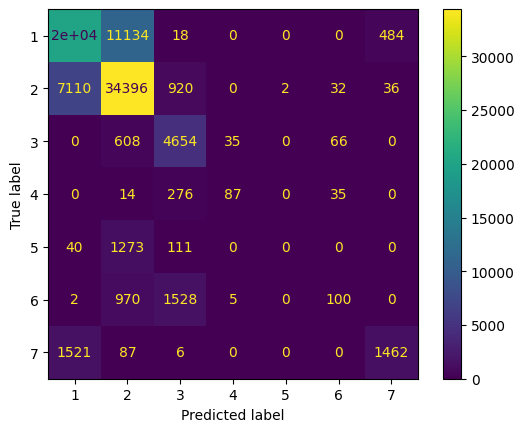

In [26]:
ConfusionMatrixDisplay.from_predictions(y_eval,SVC_predict)

### 5. Decision Tree

In [27]:
from sklearn.tree import DecisionTreeClassifier
DT_model=DecisionTreeClassifier()

### Fit Decision Tree Model on Train Data<h3/>

In [28]:
DT_model.fit(decomposited_x_train_data,y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the curre

### Decision Tree Model Prediction and Evaluation on Evaluation Data


In [29]:
DT_predict=DT_model.predict(decomposited_x_eval_data)

In [30]:
print(classification_report(y_eval,DT_predict))

              precision    recall  f1-score   support

           1       0.89      0.90      0.90     31776
           2       0.91      0.91      0.91     42496
           3       0.87      0.87      0.87      5363
           4       0.72      0.72      0.72       412
           5       0.72      0.70      0.71      1424
           6       0.76      0.77      0.77      2605
           7       0.91      0.90      0.90      3076

    accuracy                           0.89     87152
   macro avg       0.83      0.82      0.83     87152
weighted avg       0.89      0.89      0.89     87152



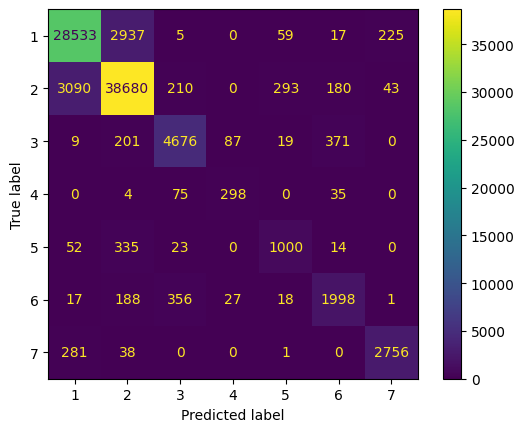

In [31]:
ConfusionMatrixDisplay.from_predictions(y_eval,DT_predict)

### Ensemble Models

### Random Forest

In [32]:
from sklearn.ensemble import RandomForestClassifier
RF_model=RandomForestClassifier()

### Fit Random Forest Model on Train Data

In [33]:
RF_model.fit(decomposited_x_train_data,y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

### Random Forest Model Prediction and Evaluation on Evaluation Data


In [34]:
RF_predict=RF_model.predict(decomposited_x_eval_data)

In [35]:
print(classification_report(y_eval,RF_predict))

              precision    recall  f1-score   support

           1       0.95      0.93      0.94     31776
           2       0.94      0.96      0.95     42496
           3       0.91      0.94      0.93      5363
           4       0.88      0.76      0.81       412
           5       0.92      0.75      0.83      1424
           6       0.88      0.83      0.86      2605
           7       0.97      0.93      0.95      3076

    accuracy                           0.94     87152
   macro avg       0.92      0.87      0.90     87152
weighted avg       0.94      0.94      0.94     87152



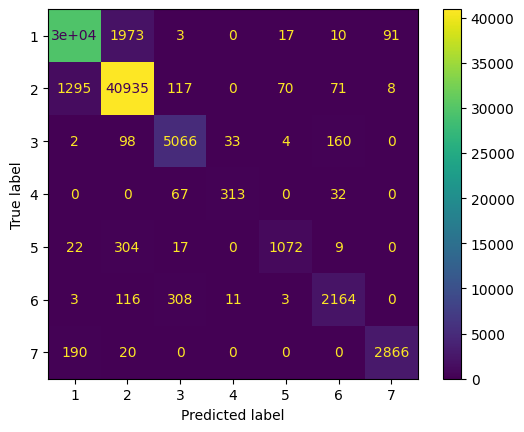

In [36]:
print(ConfusionMatrixDisplay.from_predictions(y_eval,RF_predict))

### AdaBoost

In [37]:
from sklearn.ensemble import AdaBoostClassifier
AB_model=AdaBoostClassifier()

### Fit AdaBoost Model on Train Data

Handling Class Imbalance

AdaBoost was trained using balanced sample weights because the target classes are imbalanced, allowing the model to give greater importance to underrepresented classes

Since the target classes in the Covertype dataset are imbalanced, sample weights were applied during AdaBoost training. The compute_sample_weight function was used with class_weight="balanced" to assign higher weights to samples from underrepresented classes. This helps AdaBoost pay more attention to minority classes during training and can improve their classification performance.

In [38]:
from sklearn.utils.class_weight import compute_sample_weight
AB_model.fit(decomposited_x_train_data,y_train,sample_weight=compute_sample_weight(
    class_weight="balanced",
    y=y_train))

,"estimator estimator: object, default=NoneThe base estimator from which the boosted ensemble is built.Support for sample weighting is required, as well as proper``classes_`` and ``n_classes_`` attributes. If ``None``, thenthe base estimator is :class:`~sklearn.tree.DecisionTreeClassifier`initialized with `max_depth=1`... versionadded:: 1.2 `base_estimator` was renamed to `estimator`.",None
,"n_estimators n_estimators: int, default=50The maximum number of estimators at which boosting is terminated.In case of perfect fit, the learning procedure is stopped early.Values must be in the range `[1, inf)`.",50
,"learning_rate learning_rate: float, default=1.0Weight applied to each classifier at each boosting iteration. A higherlearning rate increases the contribution of each classifier. There isa trade-off between the `learning_rate` and `n_estimators` parameters.Values must be in the range `(0.0, inf)`.",1.0
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given at each `estimator` at eachboosting iteration.Thus, it is only used when `estimator` exposes a `random_state`.Pass an int for reproducible output across multiple function calls.See :term:`Glossary `.",None


### AdaBoost Model Prediction and Evaluation on Evaluation Data


In [39]:
AB_predict=AB_model.predict(decomposited_x_eval_data)

In [40]:
print(classification_report(y_eval,AB_predict))

              precision    recall  f1-score   support

           1       0.57      0.03      0.06     31776
           2       0.51      0.48      0.50     42496
           3       0.57      0.23      0.33      5363
           4       0.06      0.30      0.10       412
           5       0.03      0.54      0.05      1424
           6       0.20      0.51      0.29      2605
           7       0.40      0.57      0.47      3076

    accuracy                           0.30     87152
   macro avg       0.33      0.38      0.25     87152
weighted avg       0.52      0.30      0.31     87152



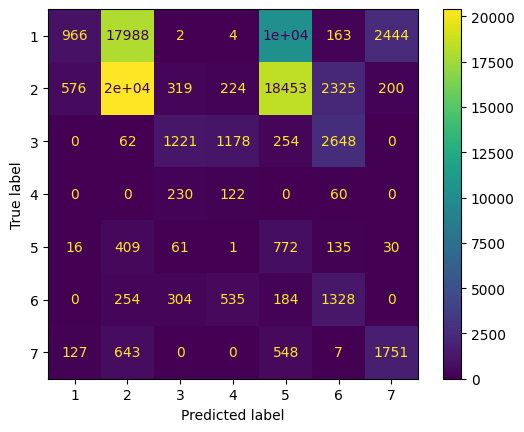

In [41]:
ConfusionMatrixDisplay.from_predictions(y_eval,AB_predict)

### GradientBoosting

In [42]:
from sklearn.ensemble import GradientBoostingClassifier
GB_model=GradientBoostingClassifier()

### Fit GradientBoosting Model on Train Data


In [43]:
GB_model.fit(decomposited_x_train_data,y_train)

,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'The function to measure the quality of a split. Supported criteria are'friedman_mse' for the mean squared error with improvement score byFriedman, 'squared_error' for mean squared error. The default value of'friedman_mse' is generally the best as it can provide a betterapproximation in some cases... versionadded:: 0.18",'friedman_mse'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, 

### GradientBoosting Model Prediction and Evaluation on Evaluation Data


In [44]:
GB_predict=GB_model.predict(decomposited_x_eval_data)

In [45]:
print(classification_report(y_eval,GB_predict))

              precision    recall  f1-score   support

           1       0.75      0.72      0.74     31776
           2       0.77      0.83      0.80     42496
           3       0.71      0.83      0.77      5363
           4       0.70      0.59      0.64       412
           5       0.78      0.21      0.33      1424
           6       0.59      0.36      0.45      2605
           7       0.82      0.66      0.73      3076

    accuracy                           0.76     87152
   macro avg       0.73      0.60      0.64     87152
weighted avg       0.76      0.76      0.75     87152



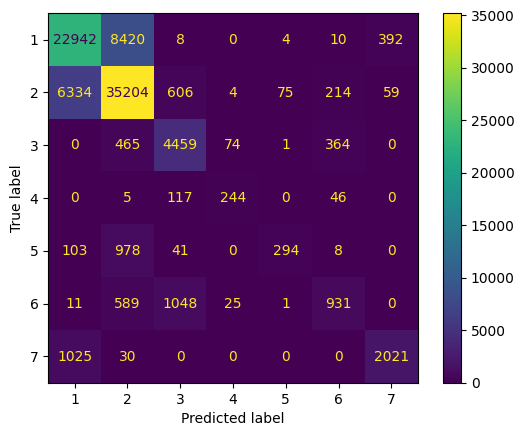

In [46]:
ConfusionMatrixDisplay.from_predictions(y_eval,GB_predict)

### <h1> Result : <h1/>

### Model Selection for Hyperparameter Tuning

Based on the baseline evaluation results, three models were selected for hyperparameter tuning: **K-Nearest Neighbors (KNN), Random Forest, and Gradient Boosting**.

- **K-Nearest Neighbors (KNN):** KNN achieved high accuracy and F1-scores and Macro F1-score, with promising precision and recall values. Therefore, tuning its hyperparameters may further improve its classification performance.

- **Random Forest:** Random Forest demonstrated strong baseline performance, achieving high accuracy and F1-scores and Macro F1-score. Its ensemble-based approach combines multiple decision trees, making it a promising candidate for further optimization. Although a single Decision Tree also performed well, Random Forest was preferred because of its potential to generalize better.

- **Gradient Boosting:** Logistic Regression and Gradient Boosting achieved relatively similar accuracy scores, but Gradient Boosting obtained a higher F1-score and Macro F1-score. Despite its considerably longer training time, it was selected because its stronger F1-score and Macro F1-score indicated better overall classification performance.


**Models Not Selected for Hyperparameter Tuning**

- **Support Vector Machine (SVM):** SVM was not selected for hyperparameter tuning because its training process was considerably time-consuming, making further optimization computationally expensive.
- **Naive Bayes:** Naive Bayes was excluded because its baseline classification performance was weaker than that of the selected models.
- **AdaBoost:** AdaBoost was not selected because its baseline performance was less competitive than that of the selected candidates.

Logistic Regression was also excluded because Gradient Boosting achieved a higher F1-score  and Macro F1-score , despite requiring considerably more training time.

In conclusion, **KNN, Random Forest, and Gradient Boosting** were selected for hyperparameter tuning. Their performance will be compared using accuracy, Macro F1-score, weighted F1-score, and training time to evaluate both overall predictive performance and classification quality across all classes.

<h3>Save Data<h3/>

In [47]:
pd.DataFrame(decomposited_x_eval_data).to_csv(r'../DATA/covertype/decomposited_x_eval_data.csv',index=False)